In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [1]:
!pip install -q monai

In [2]:
import os
import zipfile
import matplotlib.pyplot as plt
import PIL
import torch
import numpy as np

from sklearn.metrics import classification_report
from torch.utils.tensorboard import SummaryWriter
from monai.config import print_config
from monai.data import decollate_batch, DataLoader
from monai.metrics import ROCAUCMetric
from monai.networks.nets import DenseNet121
from monai.transforms import (
    Activations,
    EnsureChannelFirst,
    AsDiscrete,
    Compose,
    LoadImage,
    RandFlip,
    RandRotate,
    RandZoom,
    Resize,
    ScaleIntensity,
)
from monai.utils import set_determinism

print_config()

MONAI version: 1.6.2
Numpy version: 2.4.6
Pytorch version: 2.14.1+cu130
MONAI flags: HAS_EXT=False, USE_COMPILED=False, USE_META_DICT=False
MONAI rev id: 3c794f8e99dc432a9748d09a1bd6aa9089b3cd79
MONAI __file__: /usr/local/lib/python3.13/dist-packages/monai/__init__.py

Optional dependencies:
Pytorch Ignite version: NOT INSTALLED or UNKNOWN VERSION.
ITK version: NOT INSTALLED or UNKNOWN VERSION.
Nibabel version: 5.4.2
scikit-image version: 0.25.2
scipy version: 1.16.3
Pillow version: 11.3.0
Tensorboard version: 2.21.0
gdown version: 5.2.2
TorchVision version: 0.29.1+cu130
tqdm version: 4.67.3
lmdb version: NOT INSTALLED or UNKNOWN VERSION.
psutil version: 5.9.5
pandas version: 2.2.3
einops version: 0.8.2
transformers version: 5.22.1
mlflow version: NOT INSTALLED or UNKNOWN VERSION.
pynrrd version: NOT INSTALLED or UNKNOWN VERSION.
clearml version: NOT INSTALLED or UNKNOWN VERSION.

For details about installing the optional dependencies, please visit:
    https://monai.readthedocs.io/en/

In [3]:
zip_path = "/content/drive/MyDrive/ZhangLabData.zip"
extract_dir = "/content/data_dir"

if not os.path.exists(extract_dir):
  print("Extracting dataset from Google Drive...")
  with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)
    print("Done!")

Extracting dataset from Google Drive...
Done!


In [4]:
root_dir = "./"

In [5]:
data_dir = os.path.join(extract_dir, "CellData", "OCT", "train")

In [6]:
set_determinism(seed=0)

In [7]:
class_names = sorted(x for x in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, x)))
num_class = len(class_names)
image_files = [
    [os.path.join(data_dir, class_names[i], x) for x in os.listdir(os.path.join(data_dir, class_names[i]))]
    for i in range(num_class)
]
num_each = [len(image_files[i]) for i in range(num_class)]
image_files_list = []
image_class = []
for i in range(num_class):
    image_files_list.extend(image_files[i])
    image_class.extend([i] * num_each[i])
num_total = len(image_class)
image_width, image_height = PIL.Image.open(image_files_list[0]).size

print(f"Total image count: {num_total}")
print(f"Image dimensions: {image_width} x {image_height}")
print(f"Label names: {class_names}")
print(f"Label counts: {num_each}")

Total image count: 108309
Image dimensions: 512 x 496
Label names: ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Label counts: [37205, 11348, 8616, 51140]


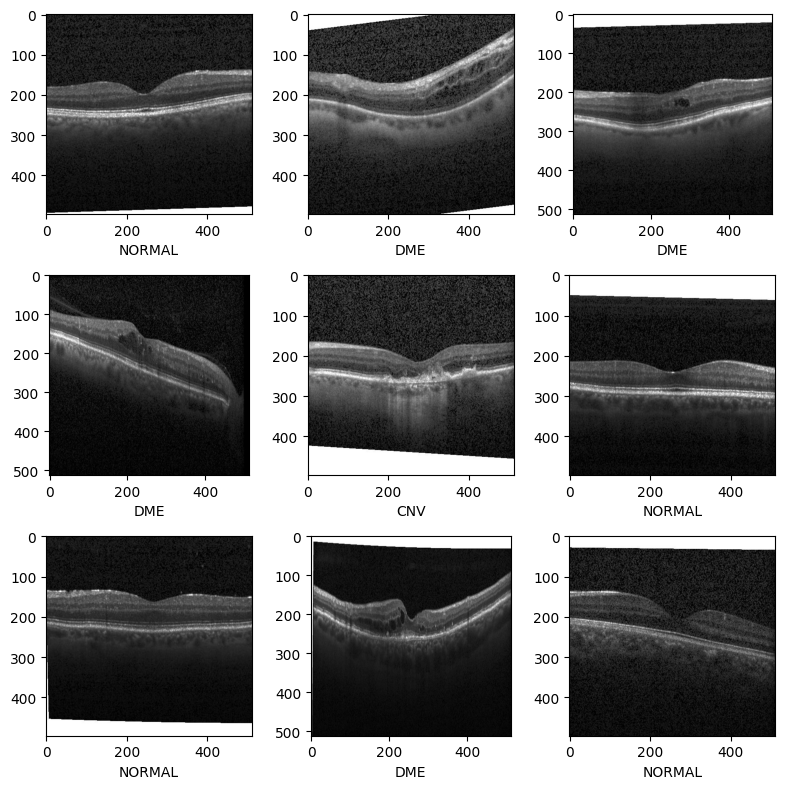

In [8]:
plt.subplots(3, 3, figsize=(8, 8))

for i, k in enumerate(np.random.randint(num_total, size=9)):
  im = PIL.Image.open(image_files_list[k])
  arr = np.array(im)
  plt.subplot(3, 3, i + 1)
  plt.xlabel(class_names[image_class[k]])
  plt.imshow(arr, cmap="gray", vmin=0, vmax=255)

plt.tight_layout()
plt.show()

In [9]:
val_frac = 0.1
test_frac = 0.1
length = len(image_files_list)
indices = np.arange(length)
np.random.shuffle(indices)

test_split = int(test_frac * length)
val_split = int(val_frac * length) + test_split
test_indices = indices[:test_split]
val_indices = indices[test_split:val_split]
train_indices = indices[val_split:]

train_x = [image_files_list[i] for i in train_indices]
train_y = [image_class[i] for i in train_indices]
val_x = [image_files_list[i] for i in val_indices]
val_y = [image_class[i] for i in val_indices]
test_x = [image_files_list[i] for i in test_indices]
test_y = [image_class[i] for i in test_indices]

print(f"Training count: {len(train_x)}, Validation count: " f"{len(val_x)}, Test count: {len(test_x)}")

Training count: 86649, Validation count: 10830, Test count: 10830


In [10]:
IMAGE_SIZE = (224, 224)

train_transforms = Compose(
    [
        LoadImage(image_only=True),
        EnsureChannelFirst(),
        ScaleIntensity(),
        Resize(IMAGE_SIZE),
        RandRotate(range_x=np.pi / 12, prob=0.5, keep_size=True),
        RandFlip(spatial_axis=1, prob=0.5),
        RandZoom(min_zoom=0.9, max_zoom=1.1, prob=0.5, keep_size=True),
    ]
)

val_transforms = Compose([LoadImage(image_only=True), EnsureChannelFirst(), ScaleIntensity(), Resize(IMAGE_SIZE)])

y_pred_trans = Compose([Activations(softmax=True)])
y_trans = Compose([AsDiscrete(to_onehot=num_class)])

In [11]:
class MedNISTDataset(torch.utils.data.Dataset):
    def __init__(self, image_files, labels, transforms):
        self.image_files = image_files
        self.labels = labels
        self.transforms = transforms

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, index):
        return self.transforms(self.image_files[index]), self.labels[index]


train_ds = MedNISTDataset(train_x, train_y, train_transforms)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)

val_ds = MedNISTDataset(val_x, val_y, val_transforms)
val_loader = DataLoader(val_ds, batch_size=64, num_workers=2)

test_ds = MedNISTDataset(test_x, test_y, val_transforms)
test_loader = DataLoader(test_ds, batch_size=64, num_workers=2)

In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = DenseNet121(spatial_dims=2, in_channels=1, out_channels=num_class).to(device)
loss_function = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), 1e-5)
max_epochs = 4
val_interval = 1
auc_metric = ROCAUCMetric()

In [13]:
best_metric = -1
best_metric_epoch = -1
epoch_loss_values = []
metric_values = []
writer = SummaryWriter()

for epoch in range(max_epochs):
    print("-" * 10)
    print(f"epoch {epoch + 1}/{max_epochs}")
    model.train()
    epoch_loss = 0
    step = 0
    for batch_data in train_loader:
        step += 1
        inputs, labels = batch_data[0].to(device), batch_data[1].to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        print(f"{step}/{len(train_ds) // train_loader.batch_size}, " f"train_loss: {loss.item():.4f}")
        epoch_len = len(train_ds) // train_loader.batch_size
        writer.add_scalar("train_loss", loss.item(), epoch_len * epoch + step)
    epoch_loss /= step
    epoch_loss_values.append(epoch_loss)
    print(f"epoch {epoch + 1} average loss: {epoch_loss:.4f}")

    if (epoch + 1) % val_interval == 0:
        model.eval()
        with torch.no_grad():
            y_pred = torch.tensor([], dtype=torch.float32, device=device)
            y = torch.tensor([], dtype=torch.long, device=device)
            for val_data in val_loader:
                val_images, val_labels = (
                    val_data[0].to(device),
                    val_data[1].to(device),
                )
                y_pred = torch.cat([y_pred, model(val_images)], dim=0)
                y = torch.cat([y, val_labels], dim=0)
            y_onehot = [y_trans(i) for i in decollate_batch(y, detach=False)]
            y_pred_act = [y_pred_trans(i) for i in decollate_batch(y_pred)]
            auc_metric(y_pred_act, y_onehot)
            result = auc_metric.aggregate()
            auc_metric.reset()
            del y_pred_act, y_onehot
            metric_values.append(result)
            acc_value = torch.eq(y_pred.argmax(dim=1), y)
            acc_metric = acc_value.sum().item() / len(acc_value)
            if result > best_metric:
                best_metric = result
                best_metric_epoch = epoch + 1
                torch.save(model.state_dict(), os.path.join(root_dir, "best_metric_model.pth"))
                print("saved new best metric model")
            print(
                f"current epoch: {epoch + 1} current AUC: {result:.4f}"
                f" current accuracy: {acc_metric:.4f}"
                f" best AUC: {best_metric:.4f}"
                f" at epoch: {best_metric_epoch}"
            )
            writer.add_scalar("val_accuracy", acc_metric, epoch + 1)

print(f"train completed, best_metric: {best_metric:.4f} " f"at epoch: {best_metric_epoch}")
writer.close()

Streaming output truncated to the last 5000 lines.
436/1353, train_loss: 0.5840
437/1353, train_loss: 0.6702
438/1353, train_loss: 0.6236
439/1353, train_loss: 0.6768
440/1353, train_loss: 0.6357
441/1353, train_loss: 0.5497
442/1353, train_loss: 0.6837
443/1353, train_loss: 0.5417
444/1353, train_loss: 0.4934
445/1353, train_loss: 0.7459
446/1353, train_loss: 0.6095
447/1353, train_loss: 0.6268
448/1353, train_loss: 0.5705
449/1353, train_loss: 0.5994
450/1353, train_loss: 0.7472
451/1353, train_loss: 0.5634
452/1353, train_loss: 0.6742
453/1353, train_loss: 0.8146
454/1353, train_loss: 0.6153
455/1353, train_loss: 0.7737
456/1353, train_loss: 0.8589
457/1353, train_loss: 0.5471
458/1353, train_loss: 0.4875
459/1353, train_loss: 0.5472
460/1353, train_loss: 0.6695
461/1353, train_loss: 0.5818
462/1353, train_loss: 0.7881
463/1353, train_loss: 0.5606
464/1353, train_loss: 0.6205
465/1353, train_loss: 0.6679
466/1353, train_loss: 0.5971
467/1353, train_loss: 0.6835
468/1353, train_loss: